# Classification des radiographies thoraciques avec VGG16 et XAI

**Classes :** COVID · Normal · Pneumonia  
**Objectif :** classifier les radiographies, évaluer le modèle, puis expliquer ses décisions avec Grad-CAM et LIME.

> **Organisation :** les cellules sont regroupées par étapes. Les cellules d'entraînement sont conservées, mais elles peuvent être ignorées si les modèles sont déjà enregistrés dans Google Drive. Les parties Grad-CAM et LIME utilisent le même modèle final et les mêmes exemples du jeu de test.

## 1. Environnement et accès aux données

**Rôle :** connecter Google Drive et définir les chemins du projet. Cette étape ne modifie pas les images ni le modèle.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/XAI_Research"
RAW_DIR = os.path.join(PROJECT_DIR, "raw_kaggle_dataset")
DATASET_ROOT = os.path.join(
    RAW_DIR, "COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset"
)
MANIFEST_PATH = os.path.join(PROJECT_DIR, "expanded_dataset_manifest.csv")
PATIENT_AUDIT_PATH = os.path.join(PROJECT_DIR, "expanded_dataset_patient_audit.csv")
SPLIT_PATH = os.path.join(PROJECT_DIR, "expanded_dataset_split.csv")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

CLASS_NAMES = ["COVID", "Normal", "Pneumonia"]
LABEL_MAP = {"covid": 0, "normal": 1, "pneumonia": 2}

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Project directory:", PROJECT_DIR)

Mounted at /content/drive
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Project directory: /content/drive/MyDrive/XAI_Research


## 2. Contrôle d'intégrité du dataset

**Rôle :** vérifier que les fichiers images sont lisibles, repérer les doublons exacts par empreinte MD5 et conserver une seule copie de chaque image identique dans sa classe.

**Résultat obtenu :** 4 575 fichiers examinés ; 4 557 images uniques conservées (COVID : 1 510, Normal : 1 525, Pneumonia : 1 522). Aucun doublon exact entre classes n'a été détecté.

In [2]:
import hashlib
from PIL import Image
from collections import defaultdict

# Cette cellule est à exécuter seulement si le manifest n'existe pas encore.
if not os.path.exists(MANIFEST_PATH):
    extensions = (".jpg", ".jpeg", ".png", ".bmp")
    records = []

    for class_name in ["covid", "normal", "pneumonia"]:
        class_dir = os.path.join(DATASET_ROOT, class_name)

        for root, _, files in os.walk(class_dir):
            for filename in sorted(files):
                if not filename.lower().endswith(extensions):
                    continue

                path = os.path.join(root, filename)
                try:
                    with Image.open(path) as img:
                        img.verify()

                    hasher = hashlib.md5()
                    with open(path, "rb") as f:
                        for chunk in iter(lambda: f.read(1024 * 1024), b""):
                            hasher.update(chunk)

                    records.append({
                        "path": path, "class": class_name,
                        "hash": hasher.hexdigest(), "valid": True
                    })
                except Exception:
                    records.append({
                        "path": path, "class": class_name,
                        "hash": None, "valid": False
                    })

    df = pd.DataFrame(records)
    valid_df = df[df["valid"]].copy()
    hash_groups = defaultdict(list)

    for idx, row in valid_df.iterrows():
        hash_groups[row["hash"]].append(idx)

    df["keep"] = False
    df["reason"] = ""
    df.loc[~df["valid"], "reason"] = "Unreadable image"

    for _, indices in hash_groups.items():
        group = df.loc[indices]

        if group["class"].nunique() > 1:
            df.loc[indices, "reason"] = "Cross-class duplicate"
            continue

        df.loc[indices[0], "keep"] = True
        df.loc[indices[0], "reason"] = "Kept"

        for duplicate_idx in indices[1:]:
            df.loc[duplicate_idx, "reason"] = "Same-class duplicate"

    df.to_csv(MANIFEST_PATH, index=False)

manifest = pd.read_csv(MANIFEST_PATH)
kept = manifest[manifest["keep"] == True].copy()

print("Files scanned:", len(manifest))
print("Readable images:", int(manifest["valid"].sum()))
print("Images retained:", len(kept))
print("\nImages per class:")
print(kept["class"].value_counts().reindex(
    ["covid", "normal", "pneumonia"], fill_value=0
))
print("\nExclusions:")
print(manifest["reason"].value_counts())
print("\nManifest:", MANIFEST_PATH)

Files scanned: 4575
Readable images: 4575
Images retained: 4557

Images per class:
class
covid        1510
normal       1525
pneumonia    1522
Name: count, dtype: int64

Exclusions:
reason
Kept                    4557
Same-class duplicate      18
Name: count, dtype: int64

Manifest: /content/drive/MyDrive/XAI_Research/expanded_dataset_manifest.csv


## 3. Identification des groupes de patients

**Rôle :** extraire les identifiants présents dans certains noms de fichiers afin de garder les images d'un même patient dans une seule partition.

**Limite importante :** les noms des images COVID ne fournissent pas d'identifiants de patients vérifiables. Pour cette classe, la séparation est donc faite au niveau des images, et non au niveau des patients.

In [3]:
import re

df = kept.copy()
df["filename"] = df["path"].apply(os.path.basename)

def extract_patient_group(row):
    filename = row["filename"]
    class_name = row["class"]

    if class_name == "covid":
        return None

    # Format NIH : 00000165_001.png
    match = re.match(r"^(\\d+)_\\d+\\.", filename)
    if match:
        return "NIH_" + match.group(1)

    # Format person : person1000_bacteria_2931.jpeg
    match = re.match(r"^person(\\d+)_", filename, re.IGNORECASE)
    if match:
        return "PERSON_" + match.group(1)

    return None

df["patient_group"] = df.apply(extract_patient_group, axis=1)
df.to_csv(PATIENT_AUDIT_PATH, index=False)

for class_name in ["covid", "normal", "pneumonia"]:
    subset = df[df["class"] == class_name]
    print(
        class_name.upper(),
        "| Images:", len(subset),
        "| IDs disponibles:", subset["patient_group"].notna().sum(),
        "| Groupes uniques:", subset["patient_group"].nunique()
    )

print("\nPatient audit saved:", PATIENT_AUDIT_PATH)

COVID | Images: 1510 | IDs disponibles: 0 | Groupes uniques: 0
NORMAL | Images: 1525 | IDs disponibles: 0 | Groupes uniques: 0
PNEUMONIA | Images: 1522 | IDs disponibles: 0 | Groupes uniques: 0

Patient audit saved: /content/drive/MyDrive/XAI_Research/expanded_dataset_patient_audit.csv


## 4. Division en entraînement, validation et test

**Rôle :** créer trois ensembles distincts avec `StratifiedGroupKFold`, en conservant autant que possible la proportion des classes et en empêchant les groupes de patients identifiés d'apparaître dans plusieurs partitions.


**Répartition obtenue :** entraînement : 3 253 images (71,38 %), validation : 648 images (14,22 %), test : 656 images (14,40 %). Les groupes de patients identifiés sont conservés dans une seule partition afin de limiter les fuites de données entre les ensembles.


In [18]:

# ============================================================
# 4. DIVISION EN ENTRAÎNEMENT, VALIDATION ET TEST
# ============================================================

import re
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# ------------------------------------------------------------
# 4.1 Chargement et préparation des données
# ------------------------------------------------------------

df = pd.read_csv(PATIENT_AUDIT_PATH).reset_index(drop=True)

# Conserver uniquement les images valides et retenues
df = df[
    (df["valid"] == True) &
    (df["keep"] == True)
].copy()

df = df.reset_index(drop=True)

# Encodage des classes
df["label"] = df["class"].map(LABEL_MAP)

assert df["label"].notna().all(), "Labels inconnus détectés."

print("Nombre total d'images :", len(df))
print("\nRépartition initiale :")
print(df["class"].value_counts())


# ------------------------------------------------------------
# 4.2 Reconstruction des identifiants de groupes
# ------------------------------------------------------------

df["split_group"] = None

for idx, row in df.iterrows():

    filename = str(row["filename"])
    class_name = str(row["class"]).strip().lower()

    # COVID : identifiant patient non disponible
    if class_name == "covid":

        df.at[idx, "split_group"] = f"COVID_IMAGE_{idx}"

    # NORMAL : extraction de l'identifiant NIH
    elif class_name == "normal":

        match = re.match(r"^(\d+)_\d+\.", filename)

        if match:
            df.at[idx, "split_group"] = (
                f"NIH_{match.group(1)}"
            )

    # PNEUMONIA : extraction NIH ou PERSON
    elif class_name == "pneumonia":

        nih_match = re.match(r"^(\d+)_\d+\.", filename)

        person_match = re.match(
            r"^person(\d+)_",
            filename,
            flags=re.IGNORECASE
        )

        if nih_match:
            df.at[idx, "split_group"] = (
                f"NIH_{nih_match.group(1)}"
            )

        elif person_match:
            df.at[idx, "split_group"] = (
                f"PERSON_{person_match.group(1)}"
            )


# Vérification des groupes
missing_groups = df["split_group"].isna().sum()

print("\nImages sans identifiant de groupe :", missing_groups)

assert missing_groups == 0, (
    "Certains identifiants de groupes n'ont pas été extraits. "
    "Vérifier les noms des fichiers."
)

print("OK : tous les groupes possèdent un identifiant.")

print("\nNombre de groupes uniques par classe :")
print(df.groupby("class")["split_group"].nunique())


# ------------------------------------------------------------
# 4.3 Fonction de sélection du meilleur fold
# ------------------------------------------------------------

def select_best_fold(data, splitter, target_fraction):

    y = data["label"].to_numpy()
    groups = data["split_group"].to_numpy()

    best_indices = None
    best_score = float("inf")

    for _, candidate_idx in splitter.split(data, y, groups):

        candidate = data.iloc[candidate_idx]

        # Écart par rapport à la proportion souhaitée
        fraction_error = abs(
            len(candidate) / len(data) - target_fraction
        )

        # Équilibre des trois classes
        proportions = (
            candidate["label"]
            .value_counts(normalize=True)
            .reindex([0, 1, 2], fill_value=0)
        )

        class_error = np.abs(
            proportions.to_numpy() - 1/3
        ).mean()

        score = fraction_error + class_error

        if score < best_score:
            best_score = score
            best_indices = candidate_idx

    return best_indices


# ------------------------------------------------------------
# 4.4 Séparation du jeu de test
# ------------------------------------------------------------

splitter_test = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

test_idx = select_best_fold(
    df,
    splitter_test,
    target_fraction=1/7
)

test = df.iloc[test_idx].copy()
train_val = df.drop(index=test_idx).copy()


# ------------------------------------------------------------
# 4.5 Séparation du jeu de validation
# ------------------------------------------------------------

validation_fraction = 0.15 / (
    1 - len(test) / len(df)
)

splitter_val = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=43
)

val_idx = select_best_fold(
    train_val,
    splitter_val,
    target_fraction=validation_fraction
)

# Sélection de la validation avec les positions
val = train_val.iloc[val_idx].copy()

# Récupération des positions restantes
train_idx = np.setdiff1d(
    np.arange(len(train_val)),
    val_idx
)

train = train_val.iloc[train_idx].copy()


# ------------------------------------------------------------
# 4.6 Construction du manifeste final
# ------------------------------------------------------------

train["split"] = "train"
val["split"] = "validation"
test["split"] = "test"

final_df = pd.concat(
    [train, val, test],
    ignore_index=True
)


# ------------------------------------------------------------
# 4.7 Vérification de la séparation
# ------------------------------------------------------------

group_split_counts = (
    final_df.groupby("split_group")["split"].nunique()
)

assert group_split_counts.max() == 1, (
    "Fuite détectée : un groupe apparaît dans plusieurs splits."
)

assert len(final_df) == len(df)
assert final_df["path"].nunique() == len(df)

# Vérifier la présence des trois classes dans chaque ensemble
expected_classes = {"covid", "normal", "pneumonia"}

for split_name in ["train", "validation", "test"]:

    subset = final_df[
        final_df["split"] == split_name
    ]

    present_classes = set(subset["class"].str.lower().unique())

    assert present_classes == expected_classes, (
        f"Classes manquantes dans {split_name} : "
        f"{expected_classes - present_classes}"
    )


# ------------------------------------------------------------
# 4.8 Affichage des résultats
# ------------------------------------------------------------

print("\n========== RÉPARTITION FINALE ==========")

print(
    pd.crosstab(
        final_df["split"],
        final_df["class"]
    )
)

for split_name in ["train", "validation", "test"]:

    subset = final_df[
        final_df["split"] == split_name
    ]

    percentage = 100 * len(subset) / len(final_df)

    print(
        f"\n{split_name.upper()} : "
        f"{len(subset)} images ({percentage:.2f}%)"
    )

    print(
        subset["class"].value_counts()
        .reindex(
            ["covid", "normal", "pneumonia"],
            fill_value=0
        )
    )

print(
    "\nGroupes présents dans plusieurs splits :",
    int((group_split_counts > 1).sum())
)

print(
    "Images COVID sans identifiant patient vérifié :",
    int((final_df["class"] == "covid").sum())
)


# ------------------------------------------------------------
# 4.9 Sauvegarde du manifeste
# ------------------------------------------------------------

final_df.to_csv(SPLIT_PATH, index=False)

print("\nManifeste sauvegardé :", SPLIT_PATH)
print("Division terminée avec succès.")


Nombre total d'images : 4557

Répartition initiale :
class
normal       1525
pneumonia    1522
covid        1510
Name: count, dtype: int64

Images sans identifiant de groupe : 0
OK : tous les groupes possèdent un identifiant.

Nombre de groupes uniques par classe :
class
covid        1510
normal        775
pneumonia    1076
Name: split_group, dtype: int64

========== RÉPARTITION FINALE ==========
class       covid  normal  pneumonia
split                               
test          216     221        219
train        1076    1090       1087
validation    218     214        216

TRAIN : 3253 images (71.38%)
class
covid        1076
normal       1090
pneumonia    1087
Name: count, dtype: int64

VALIDATION : 648 images (14.22%)
class
covid        218
normal       214
pneumonia    216
Name: count, dtype: int64

TEST : 656 images (14.40%)
class
covid        216
normal       221
pneumonia    219
Name: count, dtype: int64

Groupes présents dans plusieurs splits : 0
Images COVID sans identifia

## 5. Prétraitement et pipeline TensorFlow

**Rôle :** charger les images à partir du manifest, les redimensionner en 224 × 224, appliquer le prétraitement VGG16, puis créer les lots (`batch`) et accélérer le chargement (`prefetch`).

**Pourquoi `preprocess_input` ?** VGG16 a été pré-entraîné avec un prétraitement précis ; on applique le même traitement aux images utilisées pour l'entraînement, la validation et le test.

In [19]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

split_df = pd.read_csv(SPLIT_PATH)

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.keras.applications.vgg16.preprocess_input(image)
    return image, label

def create_dataset(dataframe, training=False):
    paths = dataframe["path"].values
    labels = dataframe["label"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_df = split_df[split_df["split"] == "train"].copy()
val_df = split_df[split_df["split"] == "validation"].copy()
test_df = split_df[split_df["split"] == "test"].copy()

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

images, labels = next(iter(train_ds))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Image batch: (16, 224, 224, 3)
Label batch: (16,)
Training batches: 204
Validation batches: 41
Test batches: 41


## 6. Modèle VGG16 — Stage 1 : extraction de caractéristiques

**Principe :** charger VGG16 avec les poids ImageNet et geler ses couches convolutives. On ajoute une tête de classification composée de Global Average Pooling, Dense(256), Dropout(0,5) et Softmax à trois sorties.

**Pourquoi cette étape ?** le réseau réutilise les caractéristiques déjà apprises par ImageNet, tandis que seule la tête de classification apprend d'abord à distinguer nos trois classes.

In [33]:

# 6. MODÈLE VGG16 — STAGE 1 : EXTRACTION DE CARACTÉRISTIQUES

from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import (
    ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger
)

# Nouveaux chemins pour le modèle entraîné avec le split corrigé
STAGE1_PATH = os.path.join(
    MODEL_DIR, "vgg16_corrected_stage1_best.keras"
)

STAGE1_LOG = os.path.join(
    MODEL_DIR, "vgg16_corrected_stage1_log.csv"
)

# Architecture VGG16
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
outputs = Dense(3, activation="softmax", name="predictions")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Callbacks
callbacks_stage1 = [
    ModelCheckpoint(
        STAGE1_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    CSVLogger(STAGE1_LOG, append=False)
]

# Entraînement
history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_stage1
)

print("Stage 1 terminé.")
print("Meilleur checkpoint :", STAGE1_PATH)


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,787 (56.64 MB)

 Trainable params: 132,099 (516.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/15
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.5268 - loss: 2.0605
Epoch 1: val_loss improved from None to 0.38397, saving model to /content/drive/MyDrive/XAI_Research/models/vgg16_corrected_stage1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/XAI_Research/models/vgg16_corrected_stage1_best.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 1425s 7s/step - accuracy: 0.6539 - loss: 1.3605 - val_accuracy: 0.8843 - val_loss: 0.3840 - learning_rate: 1.0000e-04
Epoch 2/15
203/204 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.8188 - loss: 0.5850
Epoch 2: val_loss improved from 0.38397 to 0.30157, saving model to /content/drive/MyDrive/XAI_Research/models/vgg16_corrected_stage1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/XAI_Research/models/vgg16_corrected_stage1_best.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 53s 261ms/step - accuracy: 0.8232 - loss: 0.5704 - val_accuracy: 0.8981 - val_loss: 0.3016 - learning_rate: 1.0000e-04
Epoch 3/15
203/204 ━━

## 7. Stage 2 : Fine-Tuning du bloc 5

**Principe :** recharger le meilleur modèle du Stage 1, dégeler uniquement `block5` de VGG16 et poursuivre l'entraînement avec un taux d'apprentissage plus faible (`1e-5`).

**Pourquoi ?** cette étape permet d'adapter légèrement les caractéristiques profondes aux radiographies thoraciques, tout en limitant les modifications du réseau pré-entraîné.

In [34]:

# 7. STAGE 2 : FINE-TUNING DU BLOC 5

from tensorflow.keras.models import load_model

# Nouveaux chemins pour le modèle fine-tuné
STAGE2_PATH = os.path.join(
    MODEL_DIR, "vgg16_corrected_finetuned_best.keras"
)

STAGE2_LOG = os.path.join(
    MODEL_DIR, "vgg16_corrected_stage2_log.csv"
)

# Charger le meilleur modèle du Stage 1
model = load_model(STAGE1_PATH)

base_model = model.get_layer("vgg16")
base_model.trainable = True

# Débloquer uniquement le bloc 5
for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5")

print("Couches entraînables :")

for layer in base_model.layers:
    if layer.trainable:
        print("-", layer.name)

print(
    "Paramètres entraînables :",
    sum(
        tf.keras.backend.count_params(w)
        for w in model.trainable_weights
    )
)

# Compilation avec un learning rate plus faible
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Callbacks
callbacks_stage2 = [
    ModelCheckpoint(
        STAGE2_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    CSVLogger(STAGE2_LOG, append=False)
]

# Fine-tuning
history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks_stage2
)

print("Stage 2 terminé.")
print("Meilleur checkpoint :", STAGE2_PATH)


Couches entraînables :
- block5_conv1
- block5_conv2
- block5_conv3
- block5_pool
Paramètres entraînables : 7211523
Epoch 1/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.9318 - loss: 0.1763
Epoch 1: val_loss improved from None to 0.16125, saving model to /content/drive/MyDrive/XAI_Research/models/vgg16_corrected_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/XAI_Research/models/vgg16_corrected_finetuned_best.keras
204/204 ━━━━━━━━━━━━━━━━━━━━ 66s 279ms/step - accuracy: 0.9425 - loss: 0.1620 - val_accuracy: 0.9491 - val_loss: 0.1613 - learning_rate: 1.0000e-05
Epoch 2/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.9608 - loss: 0.1124
Epoch 2: val_loss did not improve from 0.16125
204/204 ━━━━━━━━━━━━━━━━━━━━ 69s 247ms/step - accuracy: 0.9603 - loss: 0.1171 - val_accuracy: 0.9475 - val_loss: 0.1631 - learning_rate: 1.0000e-05
Epoch 3/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.9726 - loss: 0.0814
Epoch 3: val_loss


## 8. Évaluation finale sur le jeu de test

**Rôle :** évaluer le meilleur checkpoint fine-tuné sur les 656 images du jeu de test. On calcule l'accuracy, le rapport de classification, le Macro F1-score et la matrice de confusion.

**Résultats :** les métriques finales seront renseignées après le réentraînement avec le nouveau découpage des données.


41/41 ━━━━━━━━━━━━━━━━━━━━ 11s 245ms/step
========== ÉVALUATION FINALE ==========
Nombre d'images test : 656
Accuracy : 95.12%
Macro F1-score : 95.14%

Rapport de classification :
              precision    recall  f1-score   support

       COVID     0.9769    0.9769    0.9769       216
      Normal     0.9000    0.9774    0.9371       221
   Pneumonia     0.9850    0.8995    0.9403       219

    accuracy                         0.9512       656
   macro avg     0.9540    0.9513    0.9514       656
weighted avg     0.9537    0.9512    0.9513       656



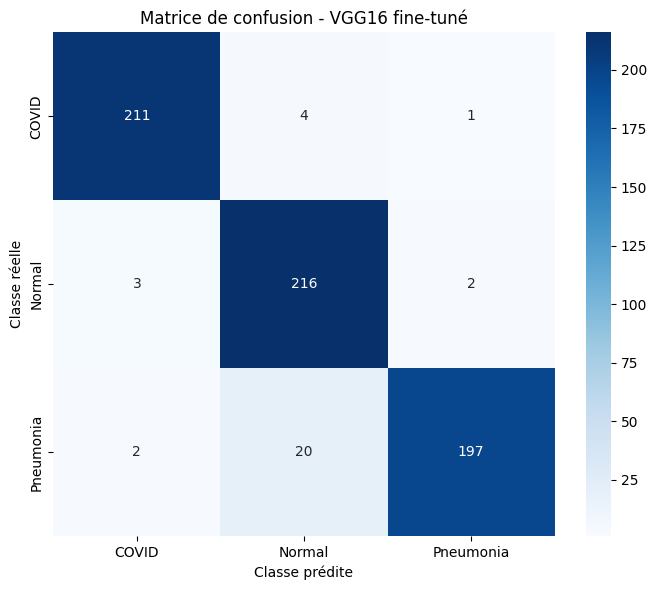

In [23]:

# 8. Évaluation finale sur le jeu de test

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Charger le meilleur modèle fine-tuné
FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "vgg16_corrected_finetuned_best.keras"
)

model = tf.keras.models.load_model(FINAL_MODEL_PATH)

# Vérifier le nombre d'images de test
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Prédictions
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Calcul des métriques
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print("========== ÉVALUATION FINALE ==========")
print("Nombre d'images test :", len(y_true))
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Macro F1-score : {macro_f1 * 100:.2f}%")

# Rapport de classification
class_names = ["COVID", "Normal", "Pneumonia"]

print("\nRapport de classification :")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    digits=4
))

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Matrice de confusion - VGG16 fine-tuné")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.show()


## 9. Chargement du modèle final pour l'explicabilité

**Rôle :** charger le checkpoint sélectionné après validation. Toutes les explications XAI qui suivent utilisent ce même modèle final.

In [35]:

# Charger le modèle final pour les explications XAI

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "vgg16_corrected_finetuned_best.keras"
)

final_model = load_model(FINAL_MODEL_PATH)

print("Modèle final chargé.")
print("Entrée :", final_model.input_shape)
print("Sortie :", final_model.output_shape)


Modèle final chargé.
Entrée : (None, 224, 224, 3)
Sortie : (None, 3)


## 10. Sélection d'exemples représentatifs

**Rôle :** choisir dans le jeu de test une prédiction correcte pour chaque classe et, si disponible, une erreur Pneumonia prédite Normal. Les mêmes exemples seront réutilisés pour Grad-CAM et LIME afin de permettre une comparaison équitable.

In [36]:
selected_images = {}

for images, labels in test_ds:
    probabilities = final_model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    true_labels = labels.numpy()

    for i in range(len(true_labels)):
        true_class = int(true_labels[i])
        pred_class = int(predictions[i])

        if true_class == pred_class and true_class not in selected_images:
            selected_images[true_class] = (
                images[i:i+1], true_class, pred_class,
                float(probabilities[i, pred_class])
            )

        if true_class == 2 and pred_class == 1:
            if "pneumonia_as_normal" not in selected_images:
                selected_images["pneumonia_as_normal"] = (
                    images[i:i+1], true_class, pred_class,
                    float(probabilities[i, pred_class])
                )

    if all(k in selected_images for k in [0, 1, 2, "pneumonia_as_normal"]):
        break

for key, (_, true_c, pred_c, confidence) in selected_images.items():
    print(
        key, "| Réelle:", CLASS_NAMES[true_c],
        "| Prédite:", CLASS_NAMES[pred_c],
        "| Confiance:", f"{confidence:.2%}"
    )

0 | Réelle: COVID | Prédite: COVID | Confiance: 99.60%
1 | Réelle: Normal | Prédite: Normal | Confiance: 98.77%
pneumonia_as_normal | Réelle: Pneumonia | Prédite: Normal | Confiance: 47.81%
2 | Réelle: Pneumonia | Prédite: Pneumonia | Confiance: 80.82%


## 11. Grad-CAM : localisation des régions influentes

**Principe :** Grad-CAM utilise les gradients de la classe choisie par le modèle par rapport aux cartes de caractéristiques de la dernière couche convolutive (`block5_conv3`). Les zones les plus activées sont affichées sous forme de heatmap.

**Lecture :** les zones chaudes indiquent les régions qui contribuent le plus au score de la classe expliquée. Elles ne constituent pas une preuve médicale ni une segmentation exacte des poumons.

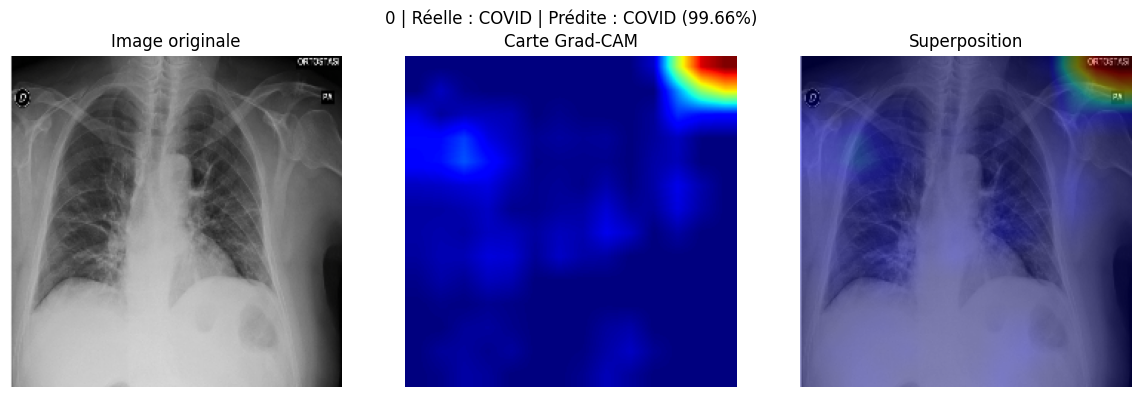

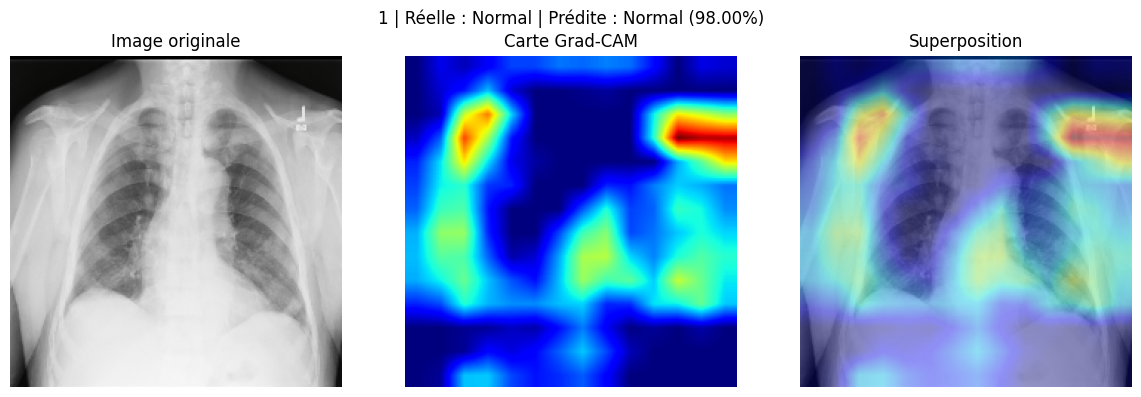

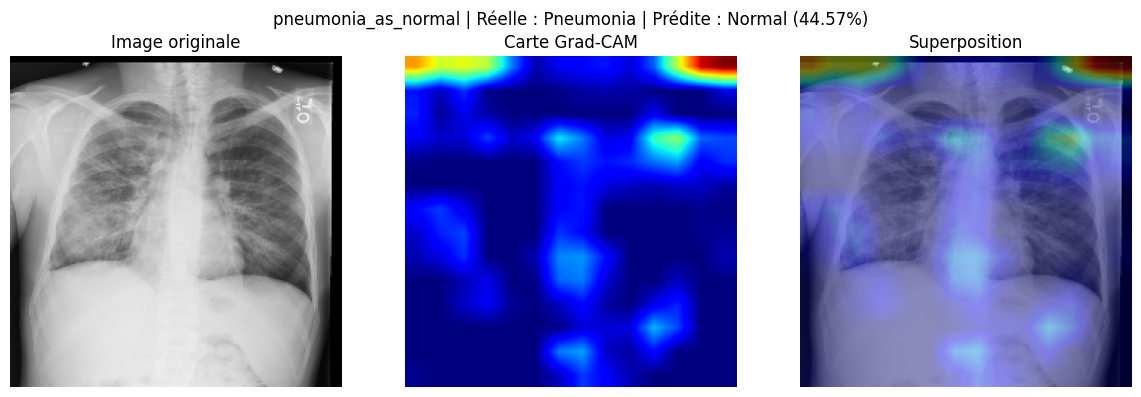

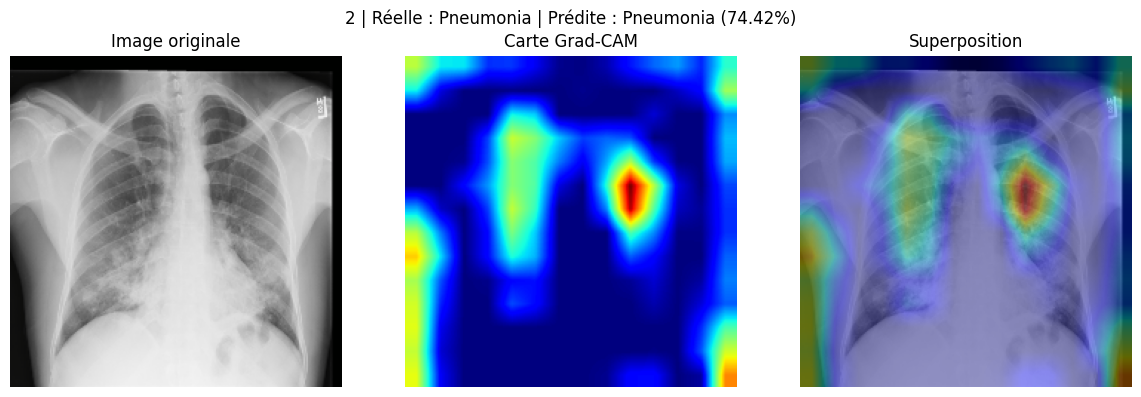

In [28]:
import cv2

base_model = final_model.get_layer("vgg16")
last_conv_layer = base_model.get_layer("block5_conv3")

feature_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[last_conv_layer.output, base_model.output]
)

head_layers = [
    layer for layer in final_model.layers
    if layer is not base_model
    and not isinstance(layer, tf.keras.layers.InputLayer)
]

def generate_gradcam(image_tensor, class_index):
    with tf.GradientTape() as tape:
        conv_outputs, features = feature_model(
            image_tensor, training=False
        )
        tape.watch(conv_outputs)

        x = features
        for layer in head_layers:
            x = layer(x, training=False)

        class_score = x[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)
    if gradients is None:
        raise RuntimeError("Gradients Grad-CAM non disponibles.")

    weights = tf.reduce_mean(gradients, axis=(1, 2))
    cam = tf.reduce_sum(
        conv_outputs * weights[:, tf.newaxis, tf.newaxis, :],
        axis=-1
    )
    cam = tf.nn.relu(cam)[0]
    cam = cam / (tf.reduce_max(cam) + tf.keras.backend.epsilon())
    return cam.numpy()

def inverse_vgg_preprocessing(image_tensor):
    # Annuler le preprocess_input VGG16 : BGR-centering -> RGB approximatif
    image = image_tensor[0].numpy().copy()
    image += np.array([103.939, 116.779, 123.68])
    image = image[..., ::-1]
    return np.clip(image, 0, 255).astype(np.uint8)

def display_gradcam(image_tensor, true_class, pred_class, confidence, title):
    original = inverse_vgg_preprocessing(image_tensor)
    heatmap = generate_gradcam(image_tensor, pred_class)
    heatmap = cv2.resize(heatmap, (original.shape[1], original.shape[0]))

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.title("Image originale")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap, cmap="jet")
    plt.title("Carte Grad-CAM")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(original)
    plt.imshow(heatmap, cmap="jet", alpha=0.4)
    plt.title("Superposition")
    plt.axis("off")

    plt.suptitle(
        f"{title} | Réelle : {CLASS_NAMES[true_class]} | "
        f"Prédite : {CLASS_NAMES[pred_class]} ({confidence:.2%})"
    )
    plt.tight_layout()
    plt.show()

for key, (image_tensor, true_c, pred_c, confidence) in selected_images.items():
    display_gradcam(image_tensor, true_c, pred_c, confidence, str(key))

## 12. LIME : expliquer pourquoi le modèle choisit une classe

**Principe :** LIME explique une prédiction pour une image précise. Il découpe l'image en superpixels, crée de nombreuses versions perturbées en masquant certaines régions, puis observe comment les probabilités du modèle changent. À partir de ces observations, il ajuste un modèle local simple qui approxime le comportement du classificateur autour de cette image.

**Comment lire les poids LIME ?**
- Un poids **positif** signifie que le superpixel contribue à soutenir la classe expliquée.
- Un poids **négatif** signifie qu'il contribue à s'opposer à cette classe.
- La valeur absolue indique l'importance relative dans l'explication locale ; ce n'est ni une probabilité ni une preuve de causalité.




EXEMPLE: 0
Classe réelle: COVID
Classe prédite par VGG16: COVID
Probabilités prédites:
  COVID: 0.9965 (99.65%)
  Normal: 0.0002 (0.02%)
  Pneumonia: 0.0033 (0.33%)


  0%|          | 0/1000 [00:00<?, ?it/s]

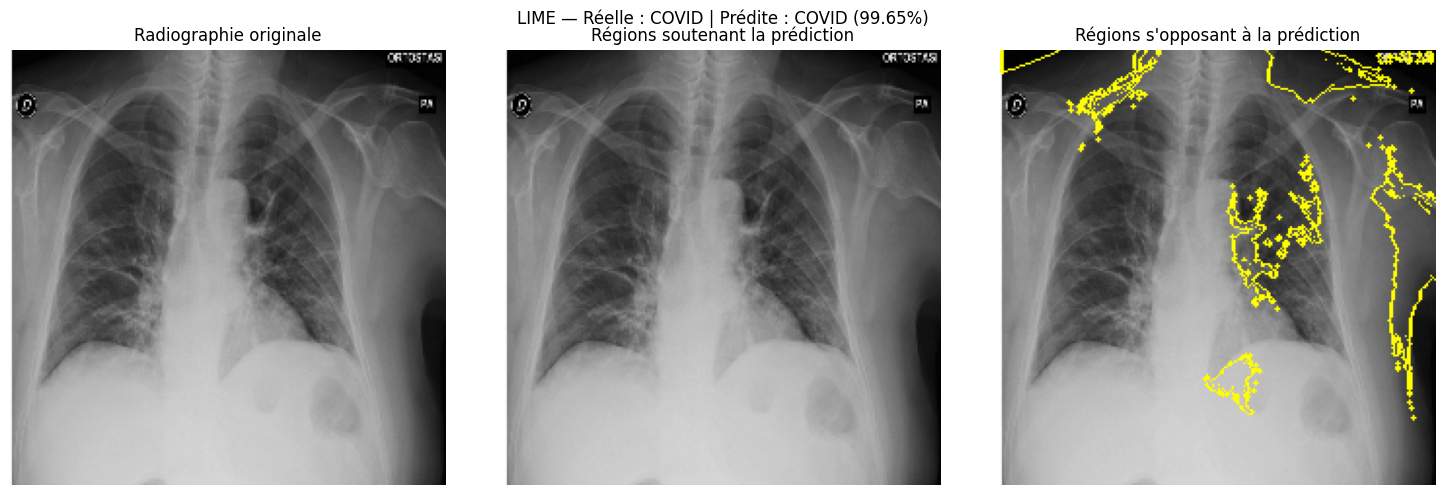


Poids LIME les plus influents pour la classe prédite:
Superpixel 33: -0.00002 -> S'oppose à COVID
Superpixel 58: -0.00002 -> S'oppose à COVID
Superpixel 10: -0.00002 -> S'oppose à COVID
Superpixel 32: -0.00002 -> S'oppose à COVID
Superpixel 7: -0.00002 -> S'oppose à COVID
Superpixel 52: -0.00002 -> S'oppose à COVID
Superpixel 3: -0.00002 -> S'oppose à COVID
Superpixel 2: -0.00002 -> S'oppose à COVID
Superpixel 37: -0.00002 -> S'oppose à COVID
Superpixel 0: -0.00002 -> S'oppose à COVID

EXEMPLE: 1
Classe réelle: Normal
Classe prédite par VGG16: Normal
Probabilités prédites:
  COVID: 0.0023 (0.23%)
  Normal: 0.9802 (98.02%)
  Pneumonia: 0.0175 (1.75%)


  0%|          | 0/1000 [00:00<?, ?it/s]

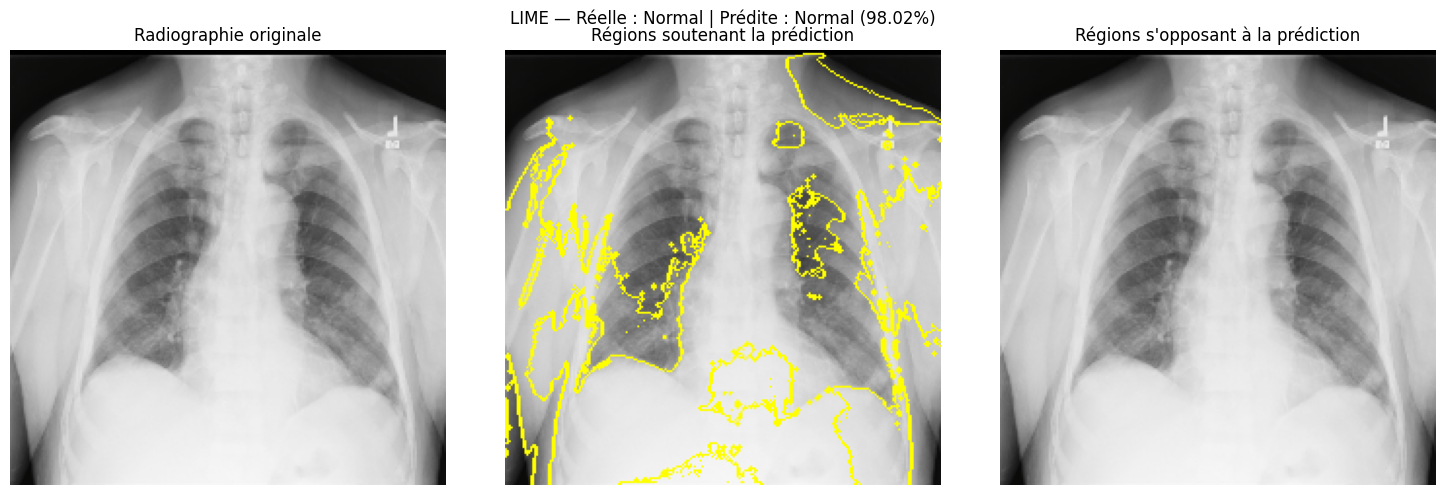


Poids LIME les plus influents pour la classe prédite:
Superpixel 12: +0.00790 -> Soutient Normal
Superpixel 51: +0.00715 -> Soutient Normal
Superpixel 40: +0.00715 -> Soutient Normal
Superpixel 29: +0.00670 -> Soutient Normal
Superpixel 26: +0.00653 -> Soutient Normal
Superpixel 43: +0.00644 -> Soutient Normal
Superpixel 44: +0.00623 -> Soutient Normal
Superpixel 56: +0.00618 -> Soutient Normal
Superpixel 33: +0.00611 -> Soutient Normal
Superpixel 31: +0.00609 -> Soutient Normal

EXEMPLE: pneumonia_as_normal
Classe réelle: Pneumonia
Classe prédite par VGG16: Normal
Probabilités prédites:
  COVID: 0.3344 (33.44%)
  Normal: 0.4221 (42.21%)
  Pneumonia: 0.2435 (24.35%)


  0%|          | 0/1000 [00:00<?, ?it/s]

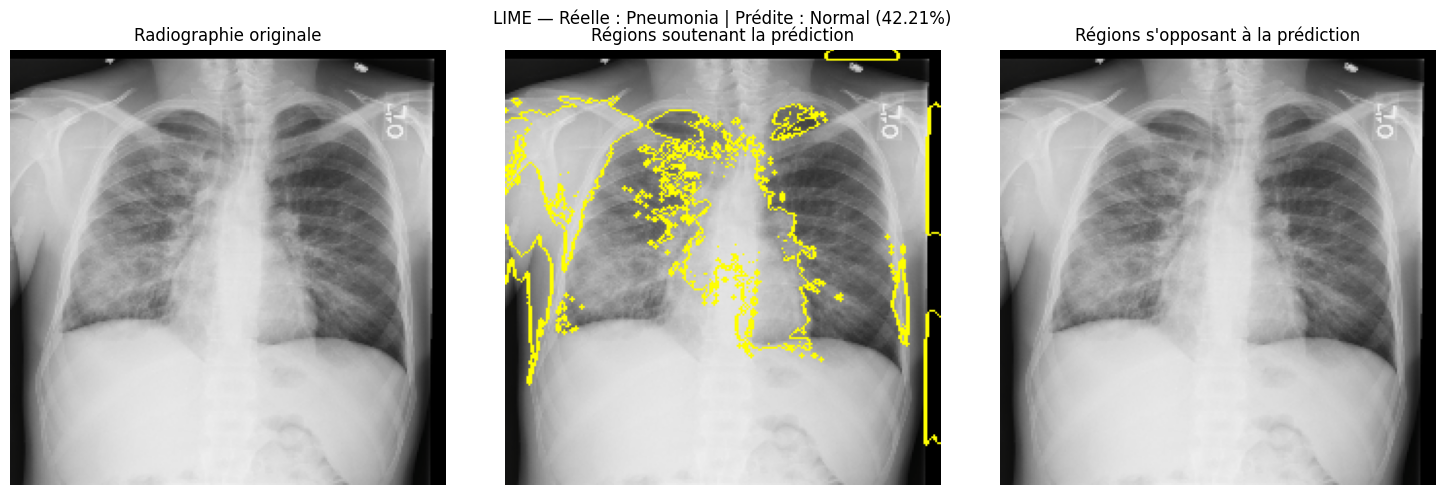


Poids LIME les plus influents pour la classe prédite:
Superpixel 43: +0.00255 -> Soutient Normal
Superpixel 5: +0.00250 -> Soutient Normal
Superpixel 39: +0.00231 -> Soutient Normal
Superpixel 28: +0.00224 -> Soutient Normal
Superpixel 45: +0.00217 -> Soutient Normal
Superpixel 26: +0.00216 -> Soutient Normal
Superpixel 36: +0.00215 -> Soutient Normal
Superpixel 18: +0.00208 -> Soutient Normal
Superpixel 48: +0.00205 -> Soutient Normal
Superpixel 70: +0.00204 -> Soutient Normal

EXEMPLE: 2
Classe réelle: Pneumonia
Classe prédite par VGG16: Pneumonia
Probabilités prédites:
  COVID: 0.0713 (7.13%)
  Normal: 0.1794 (17.94%)
  Pneumonia: 0.7493 (74.93%)


  0%|          | 0/1000 [00:00<?, ?it/s]

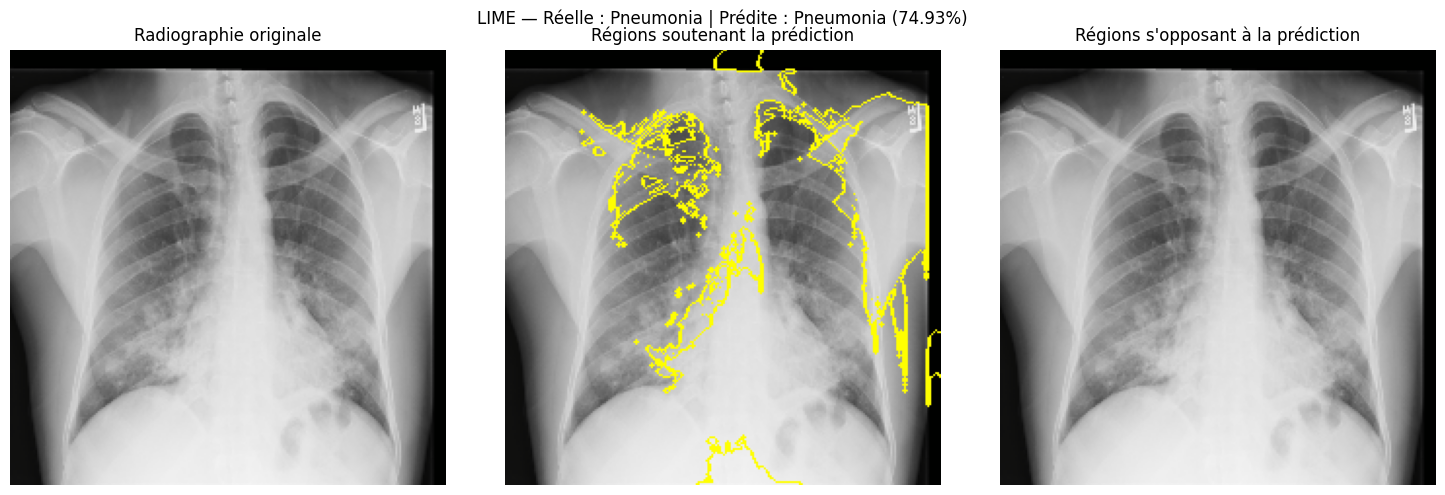


Poids LIME les plus influents pour la classe prédite:
Superpixel 25: +0.00442 -> Soutient Pneumonia
Superpixel 13: +0.00416 -> Soutient Pneumonia
Superpixel 23: +0.00409 -> Soutient Pneumonia
Superpixel 36: +0.00400 -> Soutient Pneumonia
Superpixel 62: +0.00394 -> Soutient Pneumonia
Superpixel 52: +0.00392 -> Soutient Pneumonia
Superpixel 45: +0.00391 -> Soutient Pneumonia
Superpixel 31: +0.00386 -> Soutient Pneumonia
Superpixel 4: +0.00381 -> Soutient Pneumonia
Superpixel 85: +0.00368 -> Soutient Pneumonia


In [32]:

!pip -q install lime scikit-image

import numpy as np
import matplotlib.pyplot as plt

from lime import lime_image
from skimage.segmentation import mark_boundaries
from tensorflow.keras.applications.vgg16 import preprocess_input

# LIME fournit des images RGB brutes ;
# le modèle attend le prétraitement VGG16.
def lime_predict(images):
    images = np.asarray(images, dtype=np.float32)
    processed = preprocess_input(images.copy())
    return final_model.predict(processed, verbose=0)


explainer = lime_image.LimeImageExplainer(random_state=42)


def explain_with_lime(image_tensor, true_class, title):

    # Revenir à une image RGB 224x224 non prétraitée.
    image = inverse_vgg_preprocessing(image_tensor)

    # Prédiction du modèle.
    probabilities = lime_predict(np.expand_dims(image, axis=0))[0]
    predicted_class = int(np.argmax(probabilities))

    print("\n" + "=" * 60)
    print("EXEMPLE:", title)
    print("Classe réelle:", CLASS_NAMES[true_class])
    print("Classe prédite par VGG16:", CLASS_NAMES[predicted_class])

    print("Probabilités prédites:")
    for name, probability in zip(CLASS_NAMES, probabilities):
        print(f"  {name}: {probability:.4f} ({probability:.2%})")

    # Génération de l'explication LIME.
    explanation = explainer.explain_instance(
        image=image.astype(np.double),
        classifier_fn=lime_predict,
        labels=(predicted_class,),
        hide_color=0,
        num_samples=1000,
        batch_size=32
    )

    # Régions qui soutiennent la classe prédite.
    positive_image, positive_mask = explanation.get_image_and_mask(
        predicted_class,
        positive_only=True,
        negative_only=False,
        num_features=10,
        hide_rest=False
    )

    # Régions qui s'opposent à la classe prédite.
    negative_image, negative_mask = explanation.get_image_and_mask(
        predicted_class,
        positive_only=False,
        negative_only=True,
        num_features=10,
        hide_rest=False
    )

    # Visualisation des résultats.
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image.astype(np.uint8))
    axes[0].set_title("Radiographie originale")
    axes[0].axis("off")

    axes[1].imshow(mark_boundaries(
        positive_image.astype(np.float32) / 255.0,
        positive_mask
    ))
    axes[1].set_title("Régions soutenant la prédiction")
    axes[1].axis("off")

    axes[2].imshow(mark_boundaries(
        negative_image.astype(np.float32) / 255.0,
        negative_mask
    ))
    axes[2].set_title("Régions s'opposant à la prédiction")
    axes[2].axis("off")

    fig.suptitle(
        f"LIME — Réelle : {CLASS_NAMES[true_class]} | "
        f"Prédite : {CLASS_NAMES[predicted_class]} "
        f"({probabilities[predicted_class]:.2%})"
    )

    plt.tight_layout()
    plt.show()

    # Affichage des poids locaux.
    local_weights = explanation.local_exp[predicted_class]

    print("\nPoids LIME les plus influents pour la classe prédite:")

    for segment_id, weight in sorted(
        local_weights,
        key=lambda item: abs(item[1]),
        reverse=True
    )[:10]:

        direction = "Soutient" if weight > 0 else "S'oppose à"

        print(
            f"Superpixel {segment_id}: {weight:+.5f} "
            f"-> {direction} {CLASS_NAMES[predicted_class]}"
        )

    return explanation, probabilities


# Génération des explications pour les exemples sélectionnés.
lime_explanations = {}

for key, (image_tensor, true_c, pred_c, confidence) in selected_images.items():

    lime_explanations[key] = explain_with_lime(
        image_tensor,
        true_c,
        str(key)
    )



**Grad-CAM** donne une vue globale et continue des zones associées au score d'une classe, à partir des activations convolutives.

**LIME** donne une explication locale par superpixels : certaines régions soutiennent la classe prédite, d'autres s'y opposent.

> Une heatmap ou un superpixel ne démontre pas que le modèle raisonne comme un radiologue. Les explications servent à examiner le comportement du modèle, pas à valider un diagnostic clinique.

## 14. Limites méthodologiques à mentionner

- Les identifiants de patients COVID n'étaient pas disponibles : l'indépendance patient du test n'a donc pas pu être garantie pour cette classe.
- Le dataset provient de sources hétérogènes ; le modèle peut apprendre certains indices liés à la source, à la qualité ou au format des images.
- Les performances mesurées concernent ce jeu de test et ne démontrent pas une fiabilité clinique.
- Grad-CAM et LIME sont des méthodes d'explication complémentaires, mais leurs résultats restent des approximations du comportement du modèle.